In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Environment is ready!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Environment is ready!
Pandas: 3.0.6
Scikit-learn: 1.9.1


In [3]:
import pandas as pd

df = pd.read_csv("data/load_data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


In [4]:
# Check missing values in every column
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Inspect rows where the target is missing
print("\nRows with missing Load_Type:")
display(df[df["Load_Type"].isnull()].head(10))

# Check the first and last timestamps
print("\nFirst timestamp:", df["Date_Time"].iloc[0])
print("Last timestamp:", df["Date_Time"].iloc[-1])

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Date_Time                                  0
Usage_kWh                               1559
Lagging_Current_Reactive.Power_kVarh     876
Leading_Current_Reactive_Power_kVarh    1156
CO2(tCO2)                                455
Lagging_Current_Power_Factor             350
Leading_Current_Power_Factor            1471
NSM                                      455
Load_Type                                  0
dtype: int64

Total missing values: 6322

Rows with missing Load_Type:


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type



First timestamp: 01-01-2018 00:15
Last timestamp: 31-12-2018 20:00

Duplicate rows: 0


In [5]:
# Percentage of missing values in each column
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

print("Missing-value summary:")
display(missing_summary)

# Inspect a few rows that contain missing values
print("First 10 rows containing any missing values:")
display(df[df.isnull().any(axis=1)].head(10))

# Check the target classes
print("Load_Type distribution:")
display(df["Load_Type"].value_counts())

print("\nLoad_Type percentages:")
display((df["Load_Type"].value_counts(normalize=True) * 100).round(2))

Missing-value summary:


,Missing_Count,Missing_Percentage
Date_Time,0,0.00
Usage_kWh,1559,4.45
Lagging_Current_Reactive.Power_kVarh,876,2.50
Leading_Current_Reactive_Power_kVarh,1156,3.30
CO2(tCO2),455,1.30
Lagging_Current_Power_Factor,350,1.00
Leading_Current_Power_Factor,1471,4.20
NSM,455,1.30
Load_Type,0,0.00


First 10 rows containing any missing values:


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
4,01-01-2018 01:15,3.82,4.500000,0.00,0.0,133.655666,NaN,4500.0,Light_Load
11,01-01-2018 03:00,3.24,3.640000,0.00,0.0,66.490000,NaN,10800.0,Light_Load
15,01-01-2018 04:00,3.89,5.000000,0.00,0.0,61.400000,NaN,14400.0,Light_Load
18,01-01-2018 04:45,NaN,4.540000,0.00,0.0,63.580000,100.00,17100.0,Light_Load
19,01-01-2018 05:00,3.31,10.543784,NaN,0.0,67.680000,100.00,18000.0,Light_Load
20,01-01-2018 05:15,3.56,4.070000,NaN,0.0,65.840000,100.00,18900.0,Light_Load
25,01-01-2018 06:30,3.24,3.350000,NaN,0.0,69.520000,100.00,23400.0,Light_Load
27,01-01-2018 07:00,3.31,NaN,NaN,0.0,68.400000,100.00,25200.0,Light_Load
30,01-01-2018 07:45,3.20,3.600000,0.00,0.0,66.440000,NaN,27900.0,Light_Load
49,01-01-2018 12:30,4.25,0.000000,23.15,NaN,100.000000,18.06,45000.0,Light_Load


Load_Type distribution:


Load_Type
Light_Load      18073
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64


Load_Type percentages:


Load_Type
Light_Load      51.58
Medium_Load     27.67
Maximum_Load    20.75
Name: proportion, dtype: float64

In [6]:
# Check column data types
print("DATA TYPES")
print(df.dtypes)

# Convert Date_Time to datetime
df["Date_Time"] = pd.to_datetime(
    df["Date_Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Check whether any dates failed to parse
print("\nInvalid timestamps:", df["Date_Time"].isna().sum())

# Inspect the chronological range
print("\nFirst timestamp:", df["Date_Time"].min())
print("Last timestamp:", df["Date_Time"].max())

# Check time intervals and records per month
print("\nRecords per month:")
print(df.groupby(df["Date_Time"].dt.to_period("M")).size().tail(5))

DATA TYPES
Date_Time                                   str
Usage_kWh                               float64
Lagging_Current_Reactive.Power_kVarh    float64
Leading_Current_Reactive_Power_kVarh    float64
CO2(tCO2)                               float64
Lagging_Current_Power_Factor            float64
Leading_Current_Power_Factor            float64
NSM                                     float64
Load_Type                                   str
dtype: object

Invalid timestamps: 0

First timestamp: 2018-01-01 00:00:00
Last timestamp: 2018-12-31 23:45:00

Records per month:
Date_Time
2018-08    2976
2018-09    2880
2018-10    2976
2018-11    2880
2018-12    2977
Freq: M, dtype: int64


In [7]:
# Sort observations chronologically
df = df.sort_values("Date_Time").reset_index(drop=True)

# Reserve December 2018 for final testing
test_start = pd.Timestamp("2018-12-01")

train_val_df = df[df["Date_Time"] < test_start].copy()
test_df = df[df["Date_Time"] >= test_start].copy()

print("Training and validation period:")
print(train_val_df["Date_Time"].min(), "to", train_val_df["Date_Time"].max())

print("\nFinal test period:")
print(test_df["Date_Time"].min(), "to", test_df["Date_Time"].max())

print("\nTraining/validation rows:", len(train_val_df))
print("Final test rows:", len(test_df))
print("Total rows:", len(train_val_df) + len(test_df))

Training and validation period:
2018-01-01 00:00:00 to 2018-11-30 23:45:00

Final test period:
2018-12-01 00:00:00 to 2018-12-31 23:45:00

Training/validation rows: 32064
Final test rows: 2977
Total rows: 35041


In [8]:
# Numerical columns to inspect
numeric_cols = train_val_df.select_dtypes(
    include="number"
).columns.tolist()

# Summary statistics
print("SUMMARY STATISTICS")
display(train_val_df[numeric_cols].describe().T)

# Count values outside the usual 0–100 range
power_factor_cols = [
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor"
]

print("\nPower factor values outside 0–100:")
for col in power_factor_cols:
    invalid = (
        (train_val_df[col] < 0) |
        (train_val_df[col] > 100)
    ).sum()

    print(f"{col}: {invalid}")

SUMMARY STATISTICS


,count,mean,std,min,25%,50%,75%,max
Usage_kWh,30669.0,31.597652,41.869663,0.0,3.24,5.51,54.320000,435.019069
Lagging_Current_Reactive.Power_kVarh,31269.0,15.172283,20.592703,0.0,2.99,5.33,24.550000,262.630718
Leading_Current_Reactive_Power_kVarh,31007.0,4.221254,8.944338,0.0,0.00,0.00,1.682019,78.809000
CO2(tCO2),31646.0,0.013341,0.020015,0.0,0.00,0.00,0.020000,0.188166
Lagging_Current_Power_Factor,31741.0,89.849492,39.745108,0.0,63.54,89.86,100.000000,299.996814
Leading_Current_Power_Factor,30712.0,95.465285,49.485520,0.0,99.94,100.00,100.000000,299.969494
NSM,31660.0,47997.418318,33995.534776,0.0,22500.00,45000.00,68400.000000,248821.810465



Power factor values outside 0–100:
Lagging_Current_Power_Factor: 2922
Leading_Current_Power_Factor: 2459


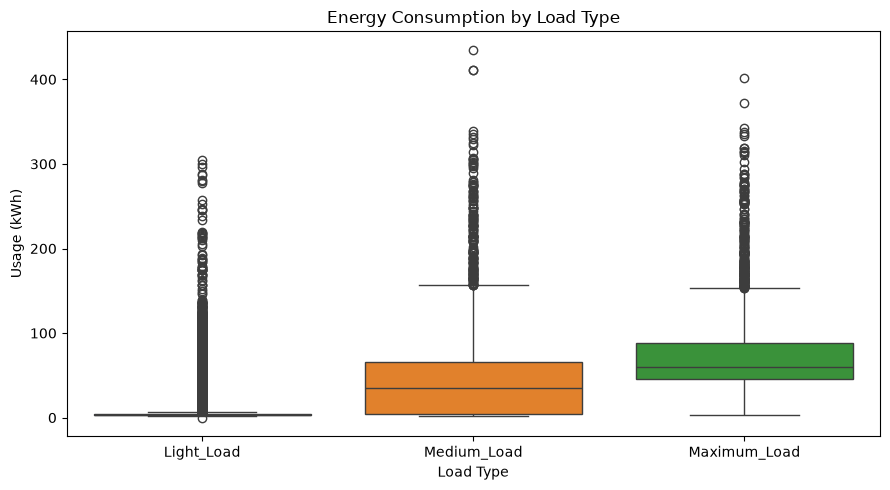

In [9]:
# Work with a copy of the development data
eda_df = train_val_df.copy()

# Extract time-based features from Date_Time
eda_df["Hour"] = eda_df["Date_Time"].dt.hour
eda_df["Day"] = eda_df["Date_Time"].dt.day
eda_df["Month"] = eda_df["Date_Time"].dt.month
eda_df["DayOfWeek"] = eda_df["Date_Time"].dt.dayofweek

# Plot energy consumption by load type
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=eda_df,
    x="Load_Type",
    y="Usage_kWh",
    hue="Load_Type",
    legend=False
)
plt.title("Energy Consumption by Load Type")
plt.xlabel("Load Type")
plt.ylabel("Usage (kWh)")
plt.tight_layout()
plt.show()

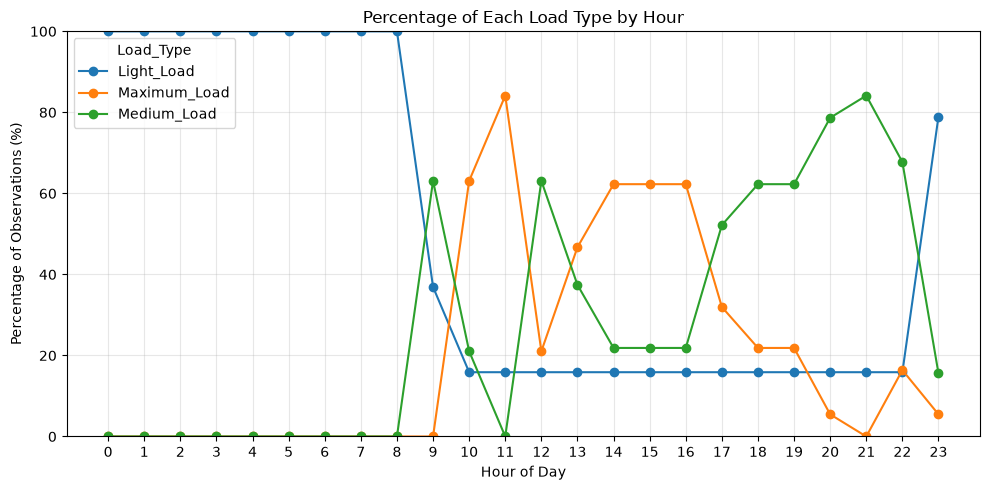

In [10]:
# Calculate the proportion of each load type within each hour
hourly_proportions = pd.crosstab(
    eda_df["Hour"],
    eda_df["Load_Type"],
    normalize="index"
) * 100

# Plot the proportions
hourly_proportions.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Percentage of Each Load Type by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Percentage of Observations (%)")
plt.xticks(range(24))
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

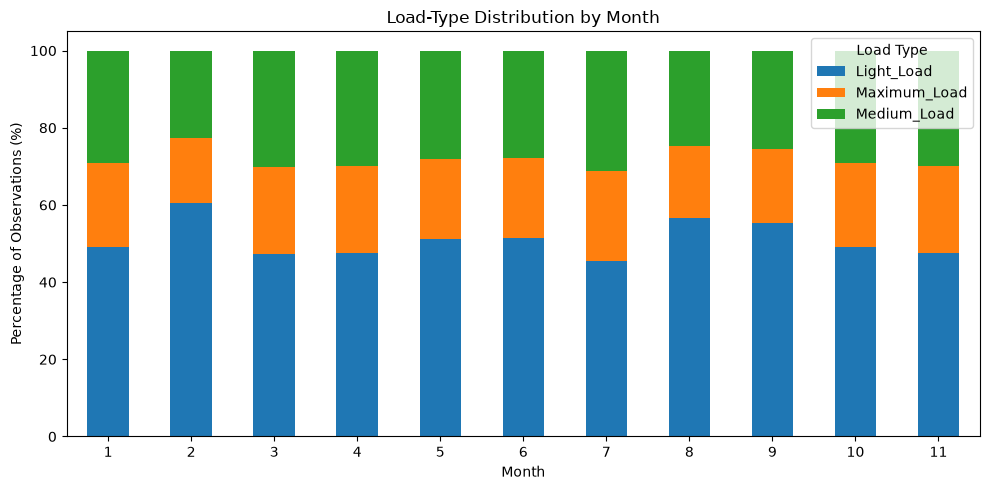

In [11]:
# Calculate the percentage of each load type within each month
monthly_proportions = pd.crosstab(
    eda_df["Month"],
    eda_df["Load_Type"],
    normalize="index"
) * 100

# Plot monthly percentages
monthly_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Load-Type Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Percentage of Observations (%)")
plt.xticks(rotation=0)
plt.legend(title="Load Type")
plt.tight_layout()
plt.show()

In [12]:
# Calculate seconds from midnight using Date_Time
calculated_nsm = (
    train_val_df["Date_Time"].dt.hour * 3600
    + train_val_df["Date_Time"].dt.minute * 60
    + train_val_df["Date_Time"].dt.second
)

# Compare original NSM with the calculated value
nsm_difference = (train_val_df["NSM"] - calculated_nsm).abs()

print("Rows with NSM different from timestamp:", (nsm_difference > 1e-6).sum())
print("Rows with NSM missing:", train_val_df["NSM"].isna().sum())

# Inspect some examples
display(
    train_val_df.loc[
        nsm_difference > 1e-6,
        ["Date_Time", "NSM"]
    ].head(10)
)

Rows with NSM different from timestamp: 3127
Rows with NSM missing: 404


,Date_Time,NSM
3,2018-01-01 00:45:00,8070.880991
8,2018-01-01 02:00:00,16589.736453
14,2018-01-01 03:30:00,36574.178080
15,2018-01-01 03:45:00,35294.963036
39,2018-01-01 09:45:00,85881.718202
108,2018-01-02 03:00:00,26606.510956
125,2018-01-02 07:15:00,39426.521592
143,2018-01-02 11:45:00,111827.445688
155,2018-01-02 14:45:00,92894.449377
163,2018-01-02 16:45:00,172574.558365


In [13]:
# Work on copies so the original dataset remains unchanged
train_val_clean = train_val_df.copy()
test_clean = test_df.copy()

# Extract time-based features from Date_Time
for data in [train_val_clean, test_clean]:
    data["Hour"] = data["Date_Time"].dt.hour
    data["DayOfWeek"] = data["Date_Time"].dt.dayofweek
    data["Month"] = data["Date_Time"].dt.month
    data["Day"] = data["Date_Time"].dt.day

    # Replace unreliable NSM with the timestamp-derived value
    data["NSM"] = (
        data["Date_Time"].dt.hour * 3600
        + data["Date_Time"].dt.minute * 60
        + data["Date_Time"].dt.second
    )

# Treat impossible power-factor percentages as missing
for data in [train_val_clean, test_clean]:
    for col in power_factor_cols:
        data.loc[
            (data[col] < 0) | (data[col] > 100),
            col
        ] = np.nan

print("Feature preparation complete.")
print("Development rows:", len(train_val_clean))
print("Test rows:", len(test_clean))

print("\nRemaining missing values in development data:")
display(train_val_clean.isnull().sum())

Feature preparation complete.
Development rows: 32064
Test rows: 2977

Remaining missing values in development data:


Date_Time                                  0
Usage_kWh                               1395
Lagging_Current_Reactive.Power_kVarh     795
Leading_Current_Reactive_Power_kVarh    1057
CO2(tCO2)                                418
Lagging_Current_Power_Factor            3245
Leading_Current_Power_Factor            3811
NSM                                        0
Load_Type                                  0
Hour                                       0
DayOfWeek                                  0
Month                                      0
Day                                        0
dtype: int64

In [14]:
# Sort development data chronologically
train_val_clean = train_val_clean.sort_values(
    "Date_Time"
).reset_index(drop=True)

# Use October 1 as the validation start
validation_start = pd.Timestamp("2018-10-01")

train_df = train_val_clean[
    train_val_clean["Date_Time"] < validation_start
].copy()

val_df = train_val_clean[
    train_val_clean["Date_Time"] >= validation_start
].copy()

print("Training period:")
print(train_df["Date_Time"].min(), "to", train_df["Date_Time"].max())

print("\nValidation period:")
print(val_df["Date_Time"].min(), "to", val_df["Date_Time"].max())

print("\nTraining rows:", len(train_df))
print("Validation rows:", len(val_df))
print("December test rows:", len(test_clean))

Training period:
2018-01-01 00:00:00 to 2018-09-30 23:45:00

Validation period:
2018-10-01 00:00:00 to 2018-11-30 23:45:00

Training rows: 26208
Validation rows: 5856
December test rows: 2977


In [15]:
# Columns that should not be used directly as model features
drop_cols = ["Date_Time", "Load_Type"]

# Separate features (X) and target (y)
X_train = train_df.drop(columns=drop_cols)
y_train = train_df["Load_Type"]

X_val = val_df.drop(columns=drop_cols)
y_val = val_df["Load_Type"]

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("\nValidation features:", X_val.shape)
print("Validation target:", y_val.shape)

print("\nFeature columns:")
print(X_train.columns.tolist())

Training features: (26208, 11)
Training target: (26208,)

Validation features: (5856, 11)
Validation target: (5856,)

Feature columns:
['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Hour', 'DayOfWeek', 'Month', 'Day']


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [17]:
baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

print("Baseline pipeline created successfully!")

Baseline pipeline created successfully!


In [18]:
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [19]:
y_val_pred = baseline_model.predict(X_val)

print("Validation Accuracy:", round(
    accuracy_score(y_val, y_val_pred), 4
))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

Validation Accuracy: 0.7037

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.92      0.85      0.88      2832
Maximum_Load       0.49      0.75      0.59      1296
 Medium_Load       0.58      0.43      0.50      1728

    accuracy                           0.70      5856
   macro avg       0.67      0.68      0.66      5856
weighted avg       0.73      0.70      0.71      5856



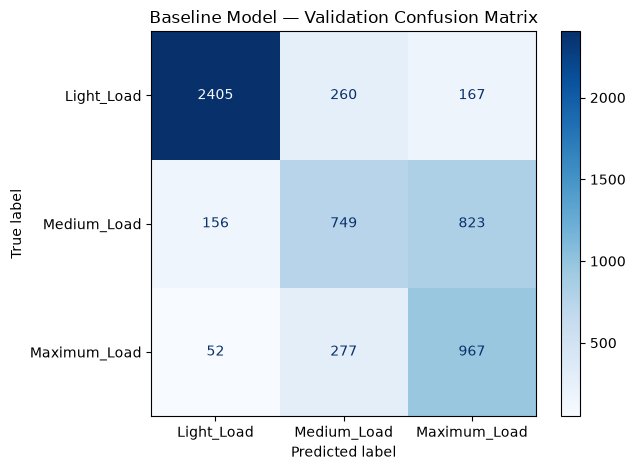

In [20]:
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=["Light_Load", "Medium_Load", "Maximum_Load"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Light_Load", "Medium_Load", "Maximum_Load"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Baseline Model — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_val_pred = rf_model.predict(X_val)

print("Random Forest Validation Accuracy:",
      round(accuracy_score(y_val, rf_val_pred), 4))

print("Random Forest Macro F1:",
      round(f1_score(y_val, rf_val_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_val, rf_val_pred, zero_division=0))

Random Forest Validation Accuracy: 0.8301
Random Forest Macro F1: 0.7875

Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.99      0.96      0.98      2832
Maximum_Load       0.65      0.67      0.66      1296
 Medium_Load       0.71      0.74      0.73      1728

    accuracy                           0.83      5856
   macro avg       0.79      0.79      0.79      5856
weighted avg       0.84      0.83      0.83      5856



In [22]:
# Compare energy consumption by month and actual load type
for month in [10, 11]:
    month_data = val_df[
        val_df["Date_Time"].dt.month == month
    ]

    print(f"\nMonth: {month}")

    display(
        month_data.groupby("Load_Type")["Usage_kWh"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )


Month: 10


,count,mean,median,std
Load_Type,,,,
Light_Load,1400,8.79,3.17,21.45
Maximum_Load,621,75.57,61.63,40.25
Medium_Load,817,38.48,31.10,39.79



Month: 11


,count,mean,median,std
Load_Type,,,,
Light_Load,1305,10.29,3.60,22.53
Maximum_Load,617,54.25,53.14,45.55
Medium_Load,829,54.97,54.94,43.91


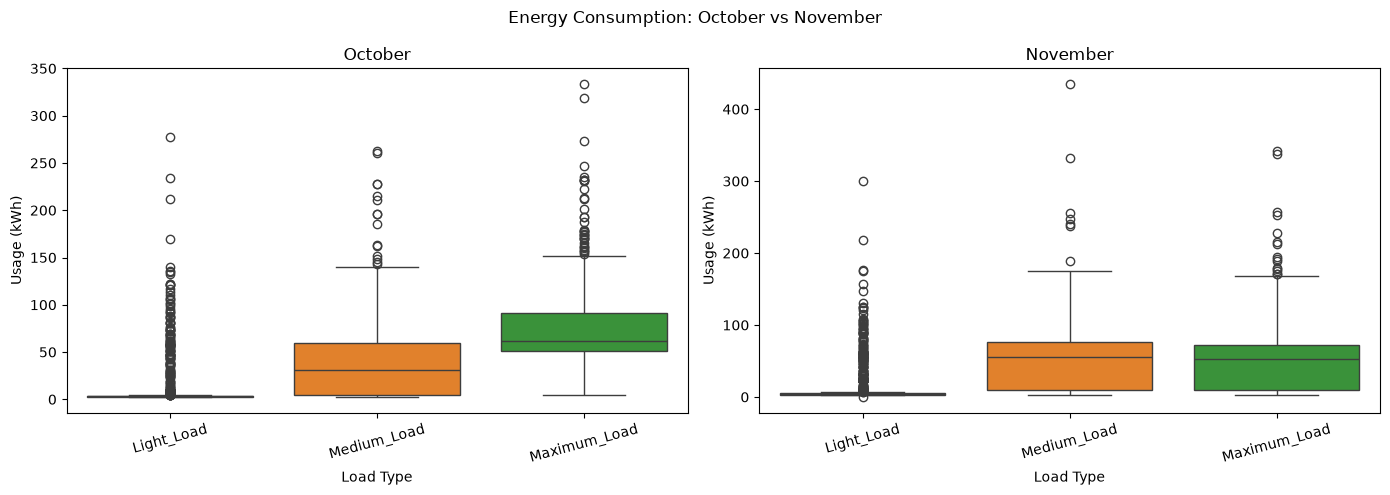

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, month in zip(axes, [10, 11]):
    month_data = val_df[
        val_df["Date_Time"].dt.month == month
    ]

    sns.boxplot(
        data=month_data,
        x="Load_Type",
        y="Usage_kWh",
        hue="Load_Type",
        legend=False,
        ax=ax
    )

    ax.set_title(
        "October" if month == 10 else "November"
    )
    ax.set_xlabel("Load Type")
    ax.set_ylabel("Usage (kWh)")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Energy Consumption: October vs November")
plt.tight_layout()
plt.show()

In [24]:
# Create cyclical time features
for data in [train_df, val_df, test_clean]:
    data["Hour_sin"] = np.sin(2 * np.pi * data["Hour"] / 24)
    data["Hour_cos"] = np.cos(2 * np.pi * data["Hour"] / 24)

    data["DayOfWeek_sin"] = np.sin(
        2 * np.pi * data["DayOfWeek"] / 7
    )
    data["DayOfWeek_cos"] = np.cos(
        2 * np.pi * data["DayOfWeek"] / 7
    )

print("Cyclical time features created.")

Cyclical time features created.


In [25]:
drop_cols = ["Date_Time", "Load_Type"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["Load_Type"]

X_val = val_df.drop(columns=drop_cols)
y_val = val_df["Load_Type"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Feature columns match:", X_train.columns.equals(X_val.columns))

Training features: (26208, 15)
Validation features: (5856, 15)
Feature columns match: True


In [26]:
rf_cyclical = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_cyclical.fit(X_train, y_train)

rf_cyclical_pred = rf_cyclical.predict(X_val)

print(
    "Validation accuracy:",
    round(accuracy_score(y_val, rf_cyclical_pred), 4)
)

print(
    "Validation macro F1:",
    round(f1_score(y_val, rf_cyclical_pred, average="macro"), 4)
)

print("\nClassification report:")
print(classification_report(
    y_val, rf_cyclical_pred, zero_division=0
))

Validation accuracy: 0.8347
Validation macro F1: 0.7912

Classification report:
              precision    recall  f1-score   support

  Light_Load       0.99      0.97      0.98      2832
Maximum_Load       0.66      0.67      0.66      1296
 Medium_Load       0.72      0.74      0.73      1728

    accuracy                           0.83      5856
   macro avg       0.79      0.79      0.79      5856
weighted avg       0.84      0.83      0.84      5856



In [27]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Calculate class weights using training labels only
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

hist_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

hist_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

hist_val_pred = hist_model.predict(X_val)

print(
    "HistGradientBoosting Accuracy:",
    round(accuracy_score(y_val, hist_val_pred), 4)
)

print(
    "HistGradientBoosting Macro F1:",
    round(f1_score(y_val, hist_val_pred, average="macro"), 4)
)

print("\nClassification report:")
print(classification_report(
    y_val,
    hist_val_pred,
    zero_division=0
))

HistGradientBoosting Accuracy: 0.8325
HistGradientBoosting Macro F1: 0.7882

Classification report:
              precision    recall  f1-score   support

  Light_Load       0.98      0.97      0.98      2832
Maximum_Load       0.66      0.67      0.66      1296
 Medium_Load       0.73      0.73      0.73      1728

    accuracy                           0.83      5856
   macro avg       0.79      0.79      0.79      5856
weighted avg       0.83      0.83      0.83      5856



In [28]:
# Evaluate HistGradientBoosting separately in October and November
hist_results = val_df[["Date_Time", "Load_Type"]].copy()
hist_results["Prediction"] = hist_val_pred
hist_results["Month"] = hist_results["Date_Time"].dt.month

for month in [10, 11]:
    month_data = hist_results[hist_results["Month"] == month]

    print(f"\nMonth: {month}")
    print("Rows:", len(month_data))

    print(
        "Accuracy:",
        round(
            accuracy_score(
                month_data["Load_Type"],
                month_data["Prediction"]
            ),
            4
        )
    )

    print(
        "Macro F1:",
        round(
            f1_score(
                month_data["Load_Type"],
                month_data["Prediction"],
                average="macro"
            ),
            4
        )
    )

    print(
        classification_report(
            month_data["Load_Type"],
            month_data["Prediction"],
            zero_division=0
        )
    )


Month: 10
Rows: 2976
Accuracy: 0.9751
Macro F1: 0.9763
              precision    recall  f1-score   support

  Light_Load       0.98      0.97      0.97      1464
Maximum_Load       0.98      1.00      0.99       648
 Medium_Load       0.96      0.97      0.97       864

    accuracy                           0.98      2976
   macro avg       0.97      0.98      0.98      2976
weighted avg       0.98      0.98      0.98      2976


Month: 11
Rows: 2880
Accuracy: 0.6851
Macro F1: 0.5983
              precision    recall  f1-score   support

  Light_Load       0.97      0.98      0.98      1368
Maximum_Load       0.33      0.33      0.33       648
 Medium_Load       0.49      0.48      0.49       864

    accuracy                           0.69      2880
   macro avg       0.60      0.60      0.60      2880
weighted avg       0.68      0.69      0.68      2880



In [29]:
# Compare class proportions across the development period
monthly_class_pct = pd.crosstab(
    train_val_clean["Date_Time"].dt.month,
    train_val_clean["Load_Type"],
    normalize="index"
) * 100

display(monthly_class_pct.round(2))

# Compare median Usage_kWh by month and Load_Type
monthly_usage = train_val_clean.pivot_table(
    index=train_val_clean["Date_Time"].dt.month,
    columns="Load_Type",
    values="Usage_kWh",
    aggfunc="median"
)

display(monthly_usage.round(2))

Load_Type,Light_Load,Maximum_Load,Medium_Load
Date_Time,,,
1,49.19,21.77,29.03
2,60.42,16.96,22.62
3,47.31,22.58,30.11
4,47.50,22.50,30.00
5,51.08,20.97,27.96
6,51.39,20.83,27.78
7,45.43,23.39,31.18
8,56.72,18.55,24.73
9,55.28,19.17,25.56


Load_Type,Light_Load,Maximum_Load,Medium_Load
Date_Time,,,
1,4.72,68.40,73.47
2,4.68,71.32,66.85
3,3.49,60.34,24.16
4,3.35,61.68,11.64
5,3.20,63.99,23.36
6,3.06,54.43,9.65
7,3.02,58.82,25.08
8,2.88,58.64,25.24
9,2.84,53.98,6.60


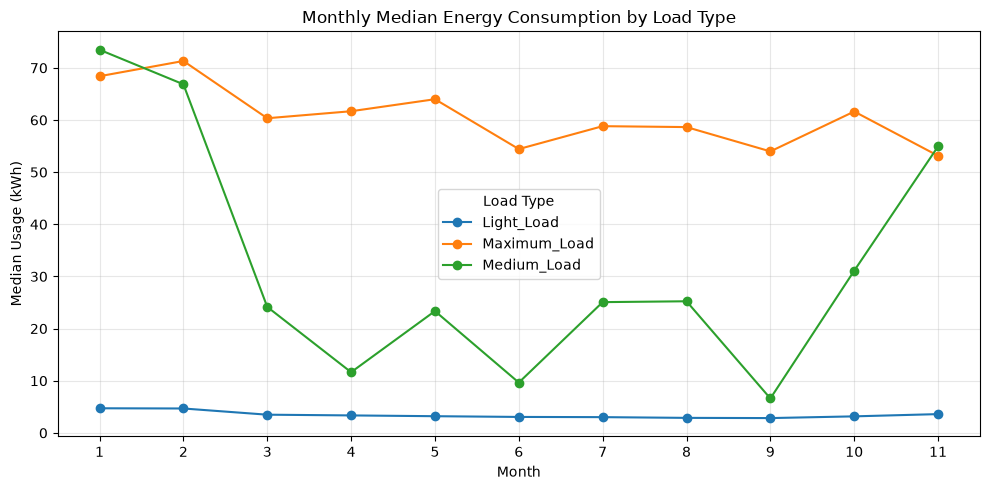

In [30]:
monthly_usage.plot(
    marker="o",
    figsize=(10, 5)
)

plt.title("Monthly Median Energy Consumption by Load Type")
plt.xlabel("Month")
plt.ylabel("Median Usage (kWh)")
plt.xticks(range(1, 12))
plt.grid(alpha=0.3)
plt.legend(title="Load Type")
plt.tight_layout()
plt.show()

In [31]:
# Use the full model's existing predictions
final_val_results = val_df[
    ["Date_Time", "Load_Type"]
].copy()

final_val_results["Prediction"] = hist_val_pred
final_val_results["Month"] = (
    final_val_results["Date_Time"].dt.month
)

for month in [10, 11]:
    subset = final_val_results[
        final_val_results["Month"] == month
    ]

    print(f"\nMonth: {month}")
    print(
        "Accuracy:",
        round(
            accuracy_score(
                subset["Load_Type"],
                subset["Prediction"]
            ),
            4
        )
    )
    print(
        "Macro F1:",
        round(
            f1_score(
                subset["Load_Type"],
                subset["Prediction"],
                average="macro"
            ),
            4
        )
    )


Month: 10
Accuracy: 0.9751
Macro F1: 0.9763

Month: 11
Accuracy: 0.6851
Macro F1: 0.5983


FINAL DECEMBER TEST RESULTS
-----------------------------------
Accuracy: 0.9086
Precision (macro): 0.8795
Recall (macro): 0.948
F1-score (macro): 0.9056

Classification Report:
              precision    recall  f1-score   support

  Light_Load       1.00      0.84      0.92      1745
Maximum_Load       0.82      1.00      0.90       528
 Medium_Load       0.82      1.00      0.90       704

    accuracy                           0.91      2977
   macro avg       0.88      0.95      0.91      2977
weighted avg       0.93      0.91      0.91      2977



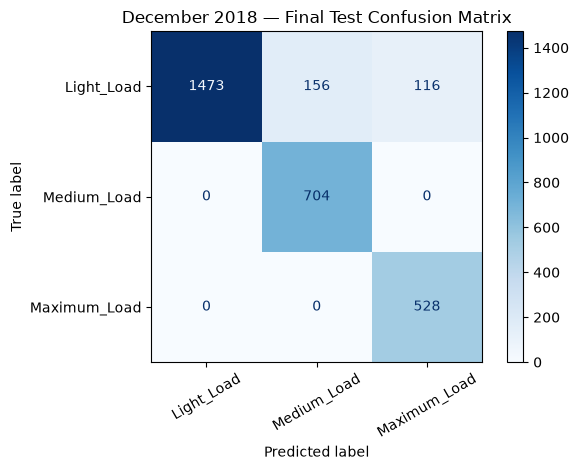

In [32]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight
import matplotlib.pyplot as plt

# Combine January–September training data and October–November validation data
dev_all = pd.concat([train_df, val_df]).sort_values(
    "Date_Time"
).reset_index(drop=True)

# Prepare features and target
drop_cols = ["Date_Time", "Load_Type"]

X_dev_all = dev_all.drop(columns=drop_cols)
y_dev_all = dev_all["Load_Type"]

X_test_final = test_clean.drop(columns=drop_cols)
y_test_final = test_clean["Load_Type"]

# Create a fresh copy of the selected model
final_model = clone(hist_model)

# Balance the classes using training data only
final_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_dev_all
)

# Train on January–November
final_model.fit(
    X_dev_all,
    y_dev_all,
    classifier__sample_weight=final_weights
)

# Evaluate on December for the first time
y_test_pred = final_model.predict(X_test_final)

print("FINAL DECEMBER TEST RESULTS")
print("-" * 35)
print("Accuracy:", round(
    accuracy_score(y_test_final, y_test_pred), 4
))
print("Precision (macro):", round(
    precision_score(
        y_test_final, y_test_pred, average="macro",
        zero_division=0
    ), 4
))
print("Recall (macro):", round(
    recall_score(
        y_test_final, y_test_pred, average="macro",
        zero_division=0
    ), 4
))
print("F1-score (macro):", round(
    f1_score(
        y_test_final, y_test_pred, average="macro",
        zero_division=0
    ), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test_final, y_test_pred, zero_division=0
))

# Confusion matrix
labels = ["Light_Load", "Medium_Load", "Maximum_Load"]

cm = confusion_matrix(
    y_test_final, y_test_pred, labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)
disp.plot(cmap="Blues", values_format="d")
plt.title("December 2018 — Final Test Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Conclusion

A machine learning pipeline was developed to classify power-system load conditions into Light_Load, Medium_Load, and Maximum_Load using electrical measurements and time-based features.

The dataset was divided chronologically to prevent future data from being used during training. January to September 2018 was used for training, October and November for validation, and December for final testing. Missing values were handled using median imputation, and invalid power-factor readings were treated as missing. Cyclical features were also created to represent hour-of-day and day-of-week patterns.

Several models were evaluated, including Logistic Regression, Random Forest, and HistGradientBoosting. HistGradientBoosting achieved the best validation performance among the evaluated models and was selected for final evaluation.

On the December 2018 test set, the final model achieved **90.86% accuracy, 87.95% macro precision, 94.80% macro recall, and a 90.56% macro F1-score**.

The validation results varied across months, particularly in November. This suggests potential temporal variation in the dataset and indicates that further evaluation on additional time periods would be useful before deploying the model. Future improvements could include investigating distribution shifts, testing additional temporal validation windows, and evaluating feature importance.

Overall, the experiment demonstrates how chronological data splitting, feature engineering, model comparison, and multiple evaluation metrics can be used to develop a power-system load classification model.